<a href="https://colab.research.google.com/github/chandrahzzz/EDA-COURSE/blob/main/SLE23bds0308.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

SLE
23BDS0308

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from sklearn.model_selection import train_test_split

In [2]:
# Load the dataset
df = pd.read_csv("https://raw.githubusercontent.com/salemprakash/EDA/main/Data/catholic.csv")
print(df.shape)
df.head()

(7430, 14)


,rownames,id,read12,math12,female,asian,hispan,black,motheduc,fatheduc,lfaminc,hsgrad,cathhs,parcath
0,1,124902,61.41,49.77,0,0,0,0,14.0,12.0,10.30895,1.0,0,1
1,2,124915,58.34,59.84,0,0,0,0,14.0,14.0,10.30895,1.0,0,1
2,3,124916,59.33,50.38,1,0,0,0,14.0,11.0,10.30895,1.0,0,1
3,4,124932,49.59,45.03,1,0,0,0,12.0,14.0,10.30895,1.0,0,1
4,5,124944,57.62,54.26,1,0,0,0,12.0,12.0,10.65726,1.0,0,1


In [3]:
# Structure and missing values
df.info()
df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7430 entries, 0 to 7429
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  7430 non-null   int64  
 1   id        7430 non-null   int64  
 2   read12    7430 non-null   float64
 3   math12    7430 non-null   float64
 4   female    7430 non-null   int64  
 5   asian     7430 non-null   int64  
 6   hispan    7430 non-null   int64  
 7   black     7430 non-null   int64  
 8   motheduc  7430 non-null   float64
 9   fatheduc  7430 non-null   float64
 10  lfaminc   7430 non-null   float64
 11  hsgrad    5970 non-null   float64
 12  cathhs    7430 non-null   int64  
 13  parcath   7430 non-null   int64  
dtypes: float64(6), int64(8)
memory usage: 812.8 KB


,0
rownames,0
id,0
read12,0
math12,0
female,0
asian,0
hispan,0
black,0
motheduc,0
fatheduc,0


In [4]:
# Summary statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
rownames,7430.0,3.715500e+03,2.145001e+03,1.000000,1.858250e+03,3.715500e+03,5.572750e+03,7.430000e+03
id,7430.0,4.589838e+06,2.744467e+06,124902.000000,2.424049e+06,4.592442e+06,7.241106e+06,7.979086e+06
read12,7430.0,5.177240e+01,9.407761e+00,29.150000,4.452500e+01,5.308000e+01,5.947000e+01,6.809000e+01
math12,7430.0,5.213362e+01,9.459117e+00,29.500000,4.502000e+01,5.253000e+01,5.985750e+01,7.137000e+01
female,7430.0,5.173620e-01,4.997321e-01,0.000000,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
asian,7430.0,5.168237e-02,2.213999e-01,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
hispan,7430.0,1.034993e-01,3.046304e-01,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
black,7430.0,7.065949e-02,2.562724e-01,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
motheduc,7430.0,1.335686e+01,2.005982e+00,8.000000,1.200000e+01,1.400000e+01,1.400000e+01,1.800000e+01
fatheduc,7430.0,1.367416e+01,2.267797e+00,8.000000,1.200000e+01,1.400000e+01,1.600000e+01,1.800000e+01


In [5]:
# Select variables and compute descriptive statistics
data = df[["read12", "math12"]].dropna()
data.agg(["mean", "std", "min", "max", "median"]).round(4)

,read12,math12
mean,51.7724,52.1336
std,9.4078,9.4591
min,29.1500,29.5000
max,68.0900,71.3700
median,53.0800,52.5300


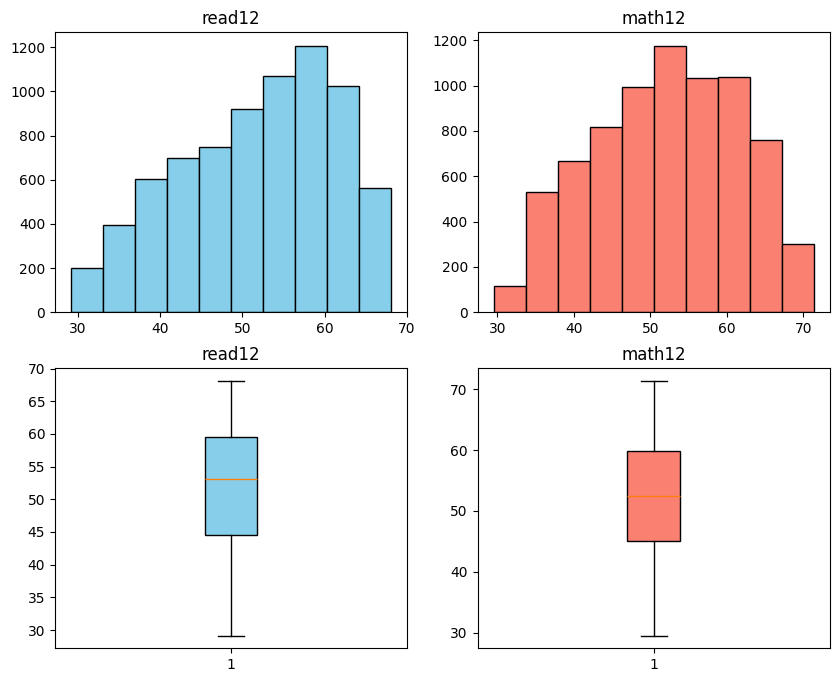

In [6]:
# Histograms and boxplots
fig, ax = plt.subplots(2, 2, figsize=(10, 8))
ax[0, 0].hist(data["read12"], color="skyblue", edgecolor="black")
ax[0, 1].hist(data["math12"], color="salmon", edgecolor="black")
ax[1, 0].boxplot(data["read12"], patch_artist=True, boxprops=dict(facecolor="skyblue"))
ax[1, 1].boxplot(data["math12"], patch_artist=True, boxprops=dict(facecolor="salmon"))
for a, t in zip(ax.flat, ["read12", "math12", "read12", "math12"]):
    a.set_title(t)
plt.show()

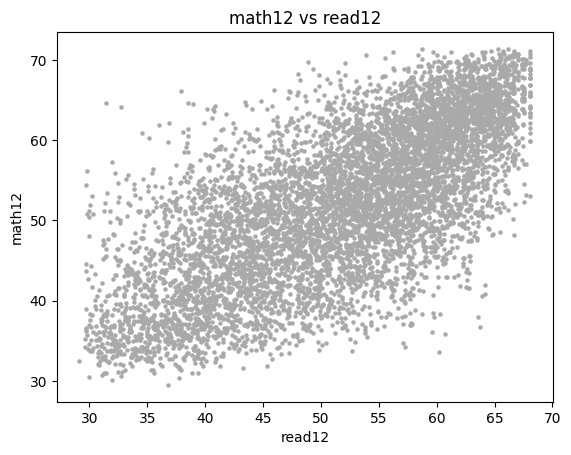

In [7]:
# Scatter plot of math12 vs read12
plt.scatter(data["read12"], data["math12"], s=5, color="darkgray")
plt.xlabel("read12")
plt.ylabel("math12")
plt.title("math12 vs read12")
plt.show()

In [8]:
# Pearson correlation test
res = stats.pearsonr(data["read12"], data["math12"])
n = len(data)
print(f"r = {res.statistic:.4f}, t = {res.statistic * np.sqrt((n - 2) / (1 - res.statistic**2)):.3f}, df = {n - 2}, p = {res.pvalue:.3g}")
print("95% CI:", np.round(res.confidence_interval(), 4))

r = 0.7104, t = 86.998, df = 7428, p = 0
95% CI: [0.699  0.7215]


In [9]:
# Train-test split (80/20)
train, test = train_test_split(data, test_size=0.2, random_state=123)
print(train.shape, test.shape)

(5944, 2) (1486, 2)


In [10]:
# Manual calculation of slope and intercept
x, y = train["read12"], train["math12"]
b1 = ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean()) ** 2).sum()
b0 = y.mean() - b1 * x.mean()
print(f"Intercept = {b0:.4f}, Slope = {b1:.4f}")

Intercept = 15.1380, Slope = 0.7142


In [11]:
# Fit the linear model and view the summary
model = smf.ols("math12 ~ read12", data=train).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 math12   R-squared:                       0.508
Model:                            OLS   Adj. R-squared:                  0.508
Method:                 Least Squares   F-statistic:                     6128.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        11:58:19   Log-Likelihood:                -19674.
No. Observations:                5944   AIC:                         3.935e+04
Df Residuals:                    5942   BIC:                         3.936e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     15.1380      0.479     31.578      0.0

In [12]:
# Confidence intervals and ANOVA table
print(model.conf_int(alpha=0.05))
sm.stats.anova_lm(model)

                   0          1
Intercept  14.198211  16.077726
read12      0.696323   0.732095


,df,sum_sq,mean_sq,F,PR(>F)
read12,1.0,269063.539156,269063.539156,6127.949772,0.0
Residual,5942.0,260898.931808,43.907595,NaN,NaN


In [13]:
# Manual R squared
SST = ((y - y.mean()) ** 2).sum()
SSE = (model.resid ** 2).sum()
SSR = SST - SSE
print(f"SST = {SST:.1f}, SSR = {SSR:.1f}, SSE = {SSE:.1f}, R2 = {SSR / SST:.4f}, Adj R2 = {model.rsquared_adj:.4f}")

SST = 529962.5, SSR = 269063.5, SSE = 260898.9, R2 = 0.5077, Adj R2 = 0.5076


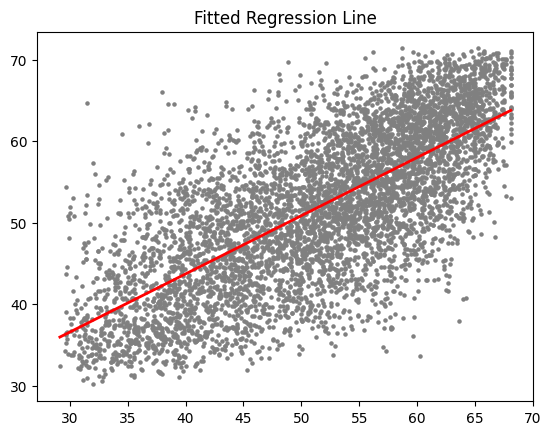

In [14]:
# Fitted regression line
plt.scatter(x, y, s=5, color="gray")
plt.plot(np.sort(x), model.params["Intercept"] + model.params["read12"] * np.sort(x), color="red", lw=2)
plt.title("Fitted Regression Line")
plt.show()

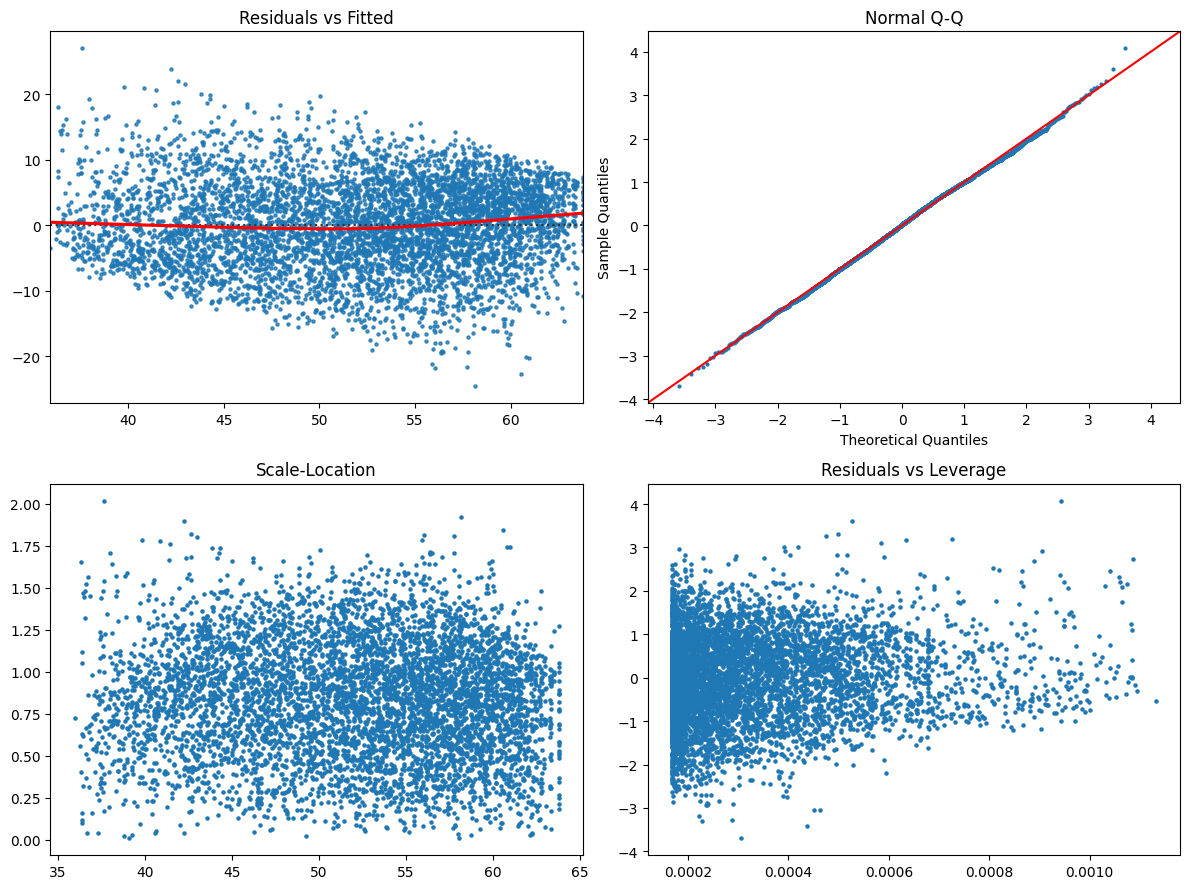

In [15]:
# Four diagnostic plots
infl = model.get_influence()
std_res = infl.resid_studentized_internal
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
sns.residplot(x=model.fittedvalues, y=model.resid, lowess=True, ax=ax[0, 0], scatter_kws={"s": 5}, line_kws={"color": "red"})
sm.qqplot(std_res, line="45", ax=ax[0, 1], markersize=2)
ax[1, 0].scatter(model.fittedvalues, np.sqrt(np.abs(std_res)), s=5)
ax[1, 1].scatter(infl.hat_matrix_diag, std_res, s=5)
for a, t in zip(ax.flat, ["Residuals vs Fitted", "Normal Q-Q", "Scale-Location", "Residuals vs Leverage"]):
    a.set_title(t)
plt.tight_layout()
plt.show()

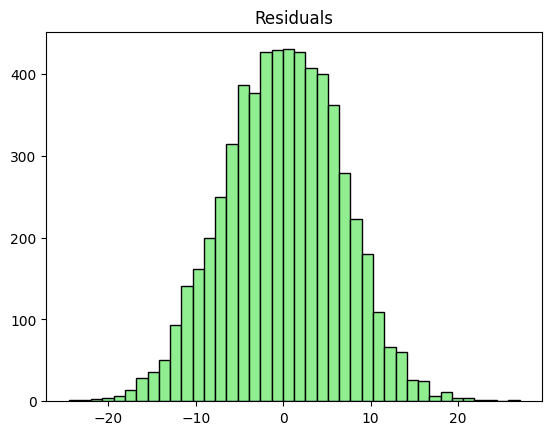

ShapiroResult(statistic=np.float64(0.9991451308026154), pvalue=np.float64(0.013763578912073188))

In [16]:
# Residual histogram and Shapiro-Wilk normality test
plt.hist(model.resid, bins=40, color="lightgreen", edgecolor="black")
plt.title("Residuals")
plt.show()
stats.shapiro(model.resid.sample(5000, random_state=123))

In [17]:
# Breusch-Pagan (homoscedasticity) and Durbin-Watson (independence) tests
bp = het_breuschpagan(model.resid, model.model.exog)
print(f"Breusch-Pagan: BP = {bp[0]:.3f}, p-value = {bp[1]:.5f}")
print(f"Durbin-Watson: DW = {durbin_watson(model.resid):.4f}")

Breusch-Pagan: BP = 21.539, p-value = 0.00000
Durbin-Watson: DW = 2.0649


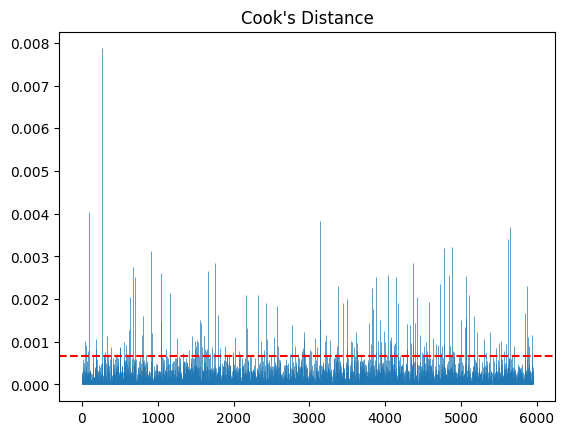

Points above 4/n: 188


In [18]:
# Influential points with Cook's distance
cooks = infl.cooks_distance[0]
plt.vlines(range(len(cooks)), 0, cooks, lw=0.5)
plt.axhline(4 / len(train), color="red", ls="--")
plt.title("Cook's Distance")
plt.show()
print("Points above 4/n:", (cooks > 4 / len(train)).sum())

In [19]:
# Predict on the test set and evaluate
test = test.assign(pred=model.predict(test))
err = test["math12"] - test["pred"]
print(f"RMSE = {np.sqrt((err**2).mean()):.4f}")
print(f"MAE  = {err.abs().mean():.4f}")
print(f"Test R2 = {1 - (err**2).sum() / ((test['math12'] - test['math12'].mean()) ** 2).sum():.4f}")

RMSE = 6.7817
MAE  = 5.4854
Test R2 = 0.4921


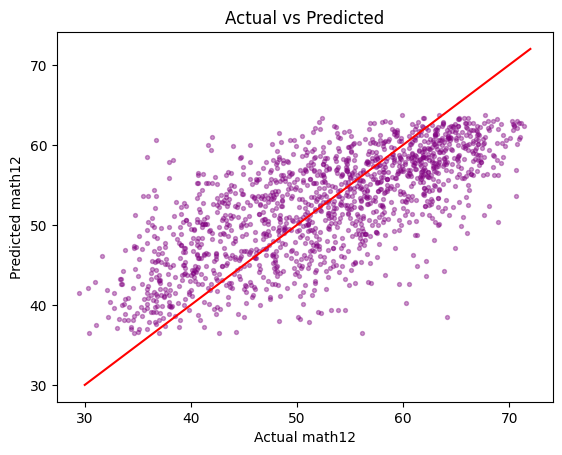

In [20]:
# Actual vs predicted
plt.scatter(test["math12"], test["pred"], s=8, alpha=0.4, color="purple")
plt.plot([30, 72], [30, 72], color="red")
plt.xlabel("Actual math12")
plt.ylabel("Predicted math12")
plt.title("Actual vs Predicted")
plt.show()

In [21]:
# Confidence and prediction intervals for new reading scores
new = pd.DataFrame({"read12": [40, 50, 60]})
model.get_prediction(new).summary_frame(alpha=0.05).round(4)

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,43.7063,0.1370,43.4378,43.9749,30.7136,56.6990
1,50.8484,0.0873,50.6772,51.0196,37.8574,63.8395
2,57.9905,0.1146,57.7659,58.2152,44.9987,70.9824


In [22]:
# Final regression equation
print(f"math12 = {model.params['Intercept']:.4f} + {model.params['read12']:.4f} * read12")

math12 = 15.1380 + 0.7142 * read12
